# 03 · Extracción de características

Este notebook corresponde al **apartado 4.2** de la memoria (4.2.1 a 4.2.5). Las funciones de cálculo están en `src/features.py`; aquí se aplican a la selección final y se muestran los resultados. Cada tabla o figura se imprime con el mismo número que tiene en la memoria.

| | |
|---|---|
| **Entrada** | `results/02_final_selection.csv` (notebook 02) y los archivos MIDI |
| **Salida** | `results/03_features_all.csv` (entrada del entrenamiento de los modelos), tablas `results/03_*.csv` y figuras 2 a 5 en `results/figures/` |

## 0. Configuración

Importa las funciones de `src/features.py`, define las rutas, lee la selección final (687 interpretaciones) y prepara el estilo de las figuras. `PIECE_NAMES` traduce los nombres internos de las piezas a los usados en la memoria.

In [152]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.features import (PIECE_BY_PITCH, PIECES, DYNAMICS_PIECES, IOI_EDGES, LHL_WEIGHTS,
                          load_notes, activity_features, grid_positions, microtiming_features,
                          position_features, onset_times_beats, ioi_features,
                          syncopation_features, dynamics_features)

DATA_DIR = ROOT / "data" / "groove"
RESULTS_DIR = ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plt.style.use("default")
plt.rcParams["savefig.facecolor"] = "white"

PIECE_NAMES = {"kick": "Bombo", "snare": "Caja", "hihat_closed": "Charles cerrado",
               "hihat_open": "Charles abierto", "tom_high": "Tom agudo", "tom_mid": "Tom medio",
               "tom_floor": "Tom de suelo", "crash": "Crash", "ride": "Ride"}

final = pd.read_csv(RESULTS_DIR / "02_final_selection.csv")
labels = final.set_index("id")[["genre", "beat_type"]]
bpm_by_id = final.set_index("id")["bpm"]


def median_by_group(features, beat_type=None):
    table = (features.join(labels).groupby(["beat_type", "genre"])[list(features.columns)]
                     .median().T)
    return table[beat_type] if beat_type else table


print("Interpretaciones en la selección final:", len(final))

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Interpretaciones en la selección final: 687


## 4.2.1. Agrupación de las notas por pieza de la batería

### Tabla 7. Número de golpes por pieza de la batería

Se leen todos los golpes de las 687 interpretaciones, se comprueba que cada nota MIDI tiene una pieza asignada en la Tabla 2 y se cuentan los golpes de cada pieza.

In [153]:
all_hits = pd.concat(
    [load_notes(DATA_DIR / path).assign(id=perf_id)
     for perf_id, path in zip(final["id"], final["midi_filename"])],
    ignore_index=True,
)
pitch_table = all_hits.groupby("pitch").size().rename("n_hits").reset_index()
pitch_table["piece"] = pitch_table["pitch"].map(PIECE_BY_PITCH)
pitch_table.to_csv(RESULTS_DIR / "03_pitch_counts.csv", index=False)

print("Golpes totales:", len(all_hits))
print("Notas MIDI distintas:", len(pitch_table))
print("Notas sin pieza asignada en la Tabla 2:", int(pitch_table["piece"].isna().sum()))

piece_table = all_hits["piece"].value_counts().rename("n_hits").to_frame()
piece_table["pct_hits"] = (100 * piece_table["n_hits"] / piece_table["n_hits"].sum()).round(1)
piece_table.index.name = "piece"
piece_table.to_csv(RESULTS_DIR / "03_piece_counts.csv")

display(piece_table.rename(index=PIECE_NAMES))

Golpes totales: 300705
Notas MIDI distintas: 22
Notas sin pieza asignada en la Tabla 2: 0


,n_hits,pct_hits
piece,,
Caja,89438,29.7
Charles cerrado,75548,25.1
Bombo,58942,19.6
Ride,38003,12.6
Tom agudo,11647,3.9
Tom de suelo,9347,3.1
Charles abierto,8824,2.9
Crash,4644,1.5
Tom medio,4312,1.4


## 4.2.2. Características de actividad por pieza

### Cálculo de las 19 características (Tabla 8)

Para cada interpretación se calculan, con `activity_features`, la densidad de golpes por compás de cada pieza (`density_<pieza>`), la proporción de golpes de cada pieza (`share_<pieza>`) y la densidad total (`density_total`). Se comprueba que no hay valores vacíos ni infinitos y que las proporciones de cada interpretación suman 1.

In [154]:
activity = pd.DataFrame(
    [activity_features(load_notes(DATA_DIR / r["midi_filename"]), r["bpm"]) for _, r in final.iterrows()],
    index=final["id"],
)
activity.to_csv(RESULTS_DIR / "03_features_activity.csv")

share_sums = activity[[f"share_{p}" for p in PIECES]].sum(axis=1)
print("Tamaño:", activity.shape)
print("Valores vacíos:", int(activity.isna().sum().sum()),
      "| valores infinitos:", int(np.isinf(activity.to_numpy()).sum()))
print("Suma de proporciones (mín / máx):", round(share_sums.min(), 4), "/", round(share_sums.max(), 4))

Tamaño: (687, 19)
Valores vacíos: 0 | valores infinitos: 0
Suma de proporciones (mín / máx): 1.0 / 1.0


### Tabla 9. Mediana de algunas características de actividad por tipo de fragmento y género

Se usa la mediana porque muchas interpretaciones no tienen golpes de algunas piezas (valor 0) y unas pocas tienen valores muy altos. La tabla completa, con las 19 características, se guarda en `03_activity_by_genre_type.csv`.

In [155]:
activity_by_group = median_by_group(activity)
activity_by_group.to_csv(RESULTS_DIR / "03_activity_by_genre_type.csv")

TABLE_9_ROWS = ["density_total", "share_kick", "share_snare", "share_hihat_closed",
                "share_tom_high", "share_ride"]
display(activity_by_group.loc[TABLE_9_ROWS].round(3))

beat_type             beat                            fill                  \
genre                 funk    jazz   latin    rock    funk    jazz   latin   
density_total       21.026  13.567  26.990  16.664  16.650  15.692  19.328   
share_kick           0.171   0.143   0.203   0.214   0.100   0.056   0.223   
share_snare          0.319   0.254   0.325   0.233   0.500   0.438   0.439   
share_hihat_closed   0.405   0.159   0.183   0.177   0.077   0.143   0.095   
share_tom_high       0.000   0.021   0.018   0.012   0.111   0.077   0.082   
share_ride           0.004   0.071   0.064   0.006   0.000   0.000   0.000   

beat_type                   
genre                 rock  
density_total       13.759  
share_kick           0.091  
share_snare          0.411  
share_hihat_closed   0.056  
share_tom_high       0.116  
share_ride           0.000

### Tabla 10. Porcentaje de interpretaciones en las que aparece cada pieza

Una pieza aparece en una interpretación si tiene al menos un golpe. Complementa a la Tabla 9, ya que la mediana vale 0 en las piezas que faltan en más de la mitad de las interpretaciones.

In [156]:
presence = (100 * (activity[[f"density_{p}" for p in PIECES]] > 0)).rename(
    columns=lambda c: c.replace("density_", ""))
presence_by_group = (presence.join(labels).groupby(["beat_type", "genre"])[PIECES].mean().T).round(1)
presence_by_group.to_csv(RESULTS_DIR / "03_piece_presence_by_genre_type.csv")

TABLE_10_ROWS = ["hihat_open", "tom_high", "tom_floor", "crash", "ride"]
display(presence_by_group.loc[TABLE_10_ROWS].rename(index=PIECE_NAMES))

beat_type        beat                    fill                  
genre            funk  jazz latin  rock  funk  jazz latin  rock
Charles abierto  88.7  52.1  70.8  62.7  28.0   7.8  13.0  16.2
Tom agudo        49.1  77.1  95.8  69.6  69.2  70.6  56.5  74.6
Tom de suelo     54.7  75.0  95.8  58.3  65.4  84.3  76.1  82.3
Crash            58.5  75.0  58.3  66.7   7.5   9.8   2.2  20.0
Ride             62.3  68.8  66.7  54.4   3.7  19.6   4.3   3.8

## 4.2.3. Características de distribución temporal

Todas las medidas temporales usan la rejilla de dieciséis casillas por compás. `grid_positions` sitúa cada golpe en la rejilla: calcula su posición en pulsos (`beat`), la casilla más cercana (`step`), su posición dentro del compás (`pos_in_bar`, de 0 a 15) y su separación respecto a esa casilla (`offset`, entre −0,5 y 0,5 casillas).

In [157]:
grid_hits = pd.concat(
    [grid_positions(load_notes(DATA_DIR / r["midi_filename"]), r["bpm"]).assign(id=r["id"])
     for _, r in final.iterrows()],
    ignore_index=True,
)
by_perf = grid_hits.groupby("id")
print("Golpes situados en la rejilla:", len(grid_hits))

Golpes situados en la rejilla: 300705


### 4.2.3.1. La rejilla del compás

#### Figura 2. Rejilla de dieciséis posiciones de un compás de 4/4

Dibuja las dieciséis casillas, los cuatro tipos de posición y el peso métrico de cada casilla (Fitch y Rosenfeld, 2007).

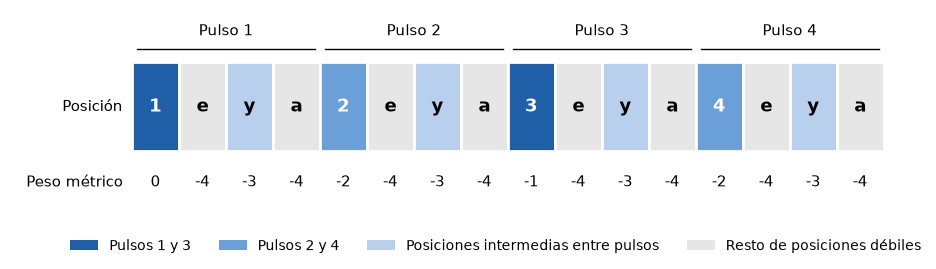

In [158]:
POS_LABELS = ["1", "e", "y", "a", "2", "e", "y", "a", "3", "e", "y", "a", "4", "e", "y", "a"]
GROUP_OF_POS = {0: "strong", 8: "strong", 4: "backbeat", 12: "backbeat",
                2: "eighth", 6: "eighth", 10: "eighth", 14: "eighth"}
GROUP_STYLE = {
    "strong": ("#1f5fa8", "Pulsos 1 y 3"),
    "backbeat": ("#6a9fd8", "Pulsos 2 y 4"),
    "eighth": ("#b8d0ee", "Posiciones intermedias entre pulsos"),
    "weak": ("#e6e6e6", "Resto de posiciones débiles"),
}

fig, ax = plt.subplots(figsize=(10, 2.8))
for i in range(16):
    group = GROUP_OF_POS.get(i, "weak")
    ax.add_patch(Rectangle((i, 0), 1, 1, facecolor=GROUP_STYLE[group][0], edgecolor="white", linewidth=2))
    ax.text(i + 0.5, 0.5, POS_LABELS[i], ha="center", va="center", fontsize=13, fontweight="bold",
            color="white" if group in ("strong", "backbeat") else "black")
    ax.text(i + 0.5, -0.35, f"{LHL_WEIGHTS[i]}", ha="center", va="center", fontsize=11)
for b in range(4):
    ax.text(b * 4 + 2, 1.35, f"Pulso {b + 1}", ha="center", va="center", fontsize=11)
    ax.plot([b * 4 + 0.1, b * 4 + 3.9], [1.15, 1.15], color="black", linewidth=1)
ax.text(-0.2, 0.5, "Posición", ha="right", va="center", fontsize=11)
ax.text(-0.2, -0.35, "Peso métrico", ha="right", va="center", fontsize=11)
ax.set_xlim(-2.6, 16.2)
ax.set_ylim(-0.8, 1.6)
ax.axis("off")
ax.legend(handles=[Patch(facecolor=c, label=l) for c, l in GROUP_STYLE.values()],
          loc="upper center", bbox_to_anchor=(0.55, -0.02), ncol=4, frameon=False, fontsize=10)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig_grid_explained.png", dpi=300, bbox_inches="tight")
plt.show()

#### Comprobación de la rejilla

Proporción de golpes situados a menos de un cuarto de casilla de la casilla más cercana. Si los golpes cayeran al azar, sería el 50 %. Se muestra también por tipo de fragmento y género (mediana de la proporción de cada interpretación).

In [159]:
close = grid_hits["offset"].abs() < 0.25
print(f"Golpes a menos de 1/4 de casilla de la rejilla: {100 * close.mean():.1f} %")

close_by_perf = close.groupby(grid_hits["id"]).mean().to_frame("share_close")
close_by_perf.to_csv(RESULTS_DIR / "03_grid_check_per_file.csv")
print("\nMediana por tipo de fragmento y género (%):")
display((100 * median_by_group(close_by_perf)).round(1))

Golpes a menos de 1/4 de casilla de la rejilla: 71.0 %

Mediana por tipo de fragmento y género (%):


beat_type    beat                    fill                  
genre        funk  jazz latin  rock  funk  jazz latin  rock
share_close  84.3  55.1  71.0  73.7  70.0  63.6  78.4  69.6

### 4.2.3.2. Microtiming

#### Figura 3. Ejemplo de cálculo del microtiming y de los intervalos entre golpes

Ejemplo ilustrativo con cinco golpes inventados y separaciones exageradas: (a) separación de cada golpe respecto a su casilla; (b) intervalo entre golpes consecutivos.

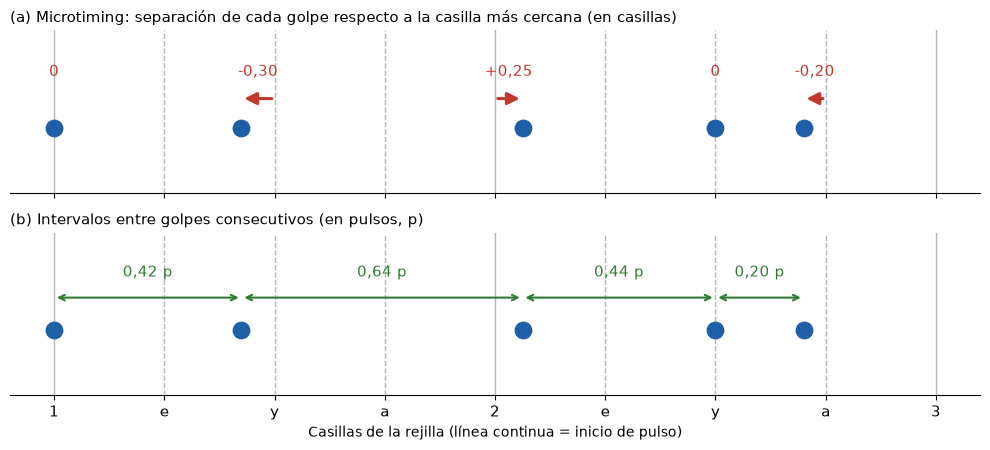

In [160]:
grid_ticks = np.arange(0, 9)
hits = np.array([0.0, 1.7, 4.25, 6.0, 6.8])
nearest = np.round(hits)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 4.6), sharex=True)
for ax in (ax1, ax2):
    for g in grid_ticks:
        ax.axvline(g, color="#b5b5b5", linewidth=1, linestyle="--" if g % 4 else "-", zorder=0)
    ax.scatter(hits, np.zeros_like(hits), s=140, color="#1f5fa8", zorder=3)
    ax.set_yticks([])
    ax.set_ylim(-0.4, 0.6)
    ax.spines[["left", "top", "right"]].set_visible(False)

for h, n in zip(hits, nearest):
    off = h - n
    if abs(off) > 1e-9:
        ax1.annotate("", xy=(h, 0.18), xytext=(n, 0.18),
                     arrowprops=dict(arrowstyle="-|>", color="#c0392b", lw=2.2, mutation_scale=18))
        ax1.text((h + n) / 2, 0.32, f"{off:+.2f}".replace(".", ","), ha="center", color="#c0392b", fontsize=11)
    else:
        ax1.text(h, 0.32, "0", ha="center", color="#c0392b", fontsize=11)
ax1.set_title("(a) Microtiming: separación de cada golpe respecto a la casilla más cercana (en casillas)",
              loc="left", fontsize=11)

for a, b in zip(hits[:-1], hits[1:]):
    ax2.annotate("", xy=(b, 0.2), xytext=(a, 0.2), arrowprops=dict(arrowstyle="<->", color="#2e7d32", lw=1.5))
    ax2.text((a + b) / 2, 0.33, f"{(b - a) / 4:.2f} p".replace(".", ","), ha="center", color="#2e7d32", fontsize=11)
ax2.set_title("(b) Intervalos entre golpes consecutivos (en pulsos, p)", loc="left", fontsize=11)
ax2.set_xticks(grid_ticks)
ax2.set_xticklabels(["1", "e", "y", "a", "2", "e", "y", "a", "3"], fontsize=11)
ax2.set_xlabel("Casillas de la rejilla (línea continua = inicio de pulso)")

fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig_micro_ioi_example.png", dpi=300, bbox_inches="tight")
plt.show()

#### Cálculo de las 3 características de microtiming

`microtiming_features` calcula la separación media (`micro_mean`), la separación media absoluta (`micro_abs_mean`) y la desviación típica de la separación (`micro_std`).

In [161]:
micro = by_perf.apply(lambda g: pd.Series(microtiming_features(g))).reindex(final["id"])
micro.to_csv(RESULTS_DIR / "03_features_microtiming.csv")
print("Tamaño:", micro.shape, "| valores vacíos:", int(micro.isna().sum().sum()))

Tamaño: (687, 3) | valores vacíos: 0


#### Comprobación del *swing*

Para cada interpretación se compara qué proporción de golpes queda cerca (a menos de un cuarto de casilla) de una rejilla de cuatro partes por pulso y de una de tres partes por pulso. Se muestra el porcentaje de interpretaciones que encajan mejor en la de tres partes, propia del *swing*.

In [162]:
def share_close_on_grid(beats, steps_per_beat):
    steps = beats * steps_per_beat
    return ((steps - steps.round()).abs() < 0.25).mean()

grid_cmp = by_perf["beat"].agg(share_16th=lambda b: share_close_on_grid(b, 4),
                               share_triplet=lambda b: share_close_on_grid(b, 3))
fits_triplet = (grid_cmp["share_triplet"] > grid_cmp["share_16th"]).to_frame("fits_triplet_better")
grid_cmp.join(fits_triplet).to_csv(RESULTS_DIR / "03_grid_16th_vs_triplet.csv")

print("Interpretaciones que encajan mejor en una rejilla de tres partes por pulso (%):")
triplet_pct = (100 * fits_triplet.join(labels).groupby(["beat_type", "genre"])["fits_triplet_better"]
                                   .mean().unstack()).round(1)
display(triplet_pct)

Interpretaciones que encajan mejor en una rejilla de tres partes por pulso (%):


genre,funk,jazz,latin,rock
beat_type,,,,
beat,5.7,62.5,18.8,26.5
fill,30.8,49.0,28.3,28.5


### 4.2.3.3. Posición de los golpes en el compás

`position_features` calcula la proporción de golpes en los pulsos 1 y 3 (`pos_strong`), en los pulsos 2 y 4 (`pos_backbeat`), en las posiciones intermedias entre pulsos (`pos_8th_offbeat`) y en el resto de posiciones débiles (`pos_16th_offbeat`). Las cuatro proporciones suman 1.

In [163]:
position = by_perf.apply(lambda g: pd.Series(position_features(g))).reindex(final["id"])
position.to_csv(RESULTS_DIR / "03_features_position.csv")
print("Tamaño:", position.shape, "| valores vacíos:", int(position.isna().sum().sum()))
print("Suma de las 4 proporciones (mín / máx):",
      round(position.sum(axis=1).min(), 4), "/", round(position.sum(axis=1).max(), 4))

Tamaño: (687, 4) | valores vacíos: 0
Suma de las 4 proporciones (mín / máx): 1.0 / 1.0


### 4.2.3.4. Intervalos entre golpes

`ioi_features` calcula los intervalos entre instantes de golpe consecutivos, en pulsos (los golpes separados menos de 1/16 de pulso cuentan como un solo instante), y la proporción de intervalos de cada categoría: muy cortos (`ioi_short`), un cuarto de pulso (`ioi_16th`), un tercio de pulso (`ioi_triplet`), medio pulso (`ioi_8th`) y un pulso o más (`ioi_quarter_plus`).

In [164]:
ioi = by_perf.apply(lambda g: pd.Series(ioi_features(g))).reindex(final["id"])
ioi.to_csv(RESULTS_DIR / "03_features_ioi.csv")
print("Tamaño:", ioi.shape, "| valores vacíos:", int(ioi.isna().sum().sum()))
print("Límites de las categorías (pulsos):", IOI_EDGES)

Tamaño: (687, 5) | valores vacíos: 0
Límites de las categorías (pulsos): [0, 0.1875, 0.29, 0.42, 0.75, inf]


#### Figura 4. Distribución de los intervalos entre golpes

Histograma de todos los intervalos de la selección final. Las líneas discontinuas son los límites entre categorías.

Intervalos totales: 199765
Intervalos muy cortos (< 0,1875 pulsos): 21.1 %
Intervalos fuera del gráfico (> 1,25 pulsos): 0.1 %


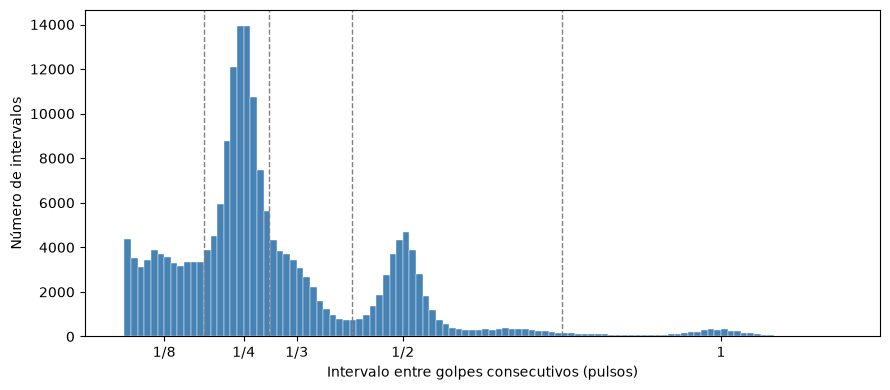

In [165]:
iois_by_perf = {perf_id: np.diff(onset_times_beats(g)) for perf_id, g in by_perf}
all_iois = np.concatenate(list(iois_by_perf.values()))

print("Intervalos totales:", len(all_iois))
print(f"Intervalos muy cortos (< 0,1875 pulsos): {100 * (all_iois < 0.1875).mean():.1f} %")
print(f"Intervalos fuera del gráfico (> 1,25 pulsos): {100 * (all_iois > 1.25).mean():.1f} %")

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(all_iois, bins=120, range=(0, 1.25), color="steelblue", edgecolor="white", linewidth=0.3)
for edge in IOI_EDGES[1:-1]:
    ax.axvline(edge, color="gray", linestyle="--", linewidth=1)
ax.set_xticks([0.125, 0.25, 1 / 3, 0.5, 1.0])
ax.set_xticklabels(["1/8", "1/4", "1/3", "1/2", "1"])
ax.set_xlabel("Intervalo entre golpes consecutivos (pulsos)")
ax.set_ylabel("Número de intervalos")
ax.set_xlim(0, 1.25)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig_ioi_histogram.png", dpi=300)
plt.show()

#### Intervalos muy cortos por tipo de fragmento y género

Porcentaje de intervalos muy cortos dentro de cada grupo. Sirve para comprobar si son redobles rápidos (serían más frecuentes en los *fills*) o golpes casi simultáneos.

In [166]:
short_share = pd.Series({perf_id: (v < 0.1875).mean() for perf_id, v in iois_by_perf.items()})
n_iois = pd.Series({perf_id: len(v) for perf_id, v in iois_by_perf.items()})
short_counts = (short_share * n_iois).to_frame("short").assign(total=n_iois).join(labels)
short_pct = short_counts.groupby(["beat_type", "genre"])[["short", "total"]].sum()
display((100 * short_pct["short"] / short_pct["total"]).unstack().round(1))

genre,funk,jazz,latin,rock
beat_type,,,,
beat,19.6,16.9,32.5,14.2
fill,23.2,17.9,11.2,23.2


### 4.2.3.5. Síncopa

#### Figura 5. Ejemplo de cálculo de la síncopa

Un golpe en la posición «y» (peso −3) seguido de silencio en el pulso 3 (peso −1) produce una síncopa de intensidad (−1) − (−3) = 2.

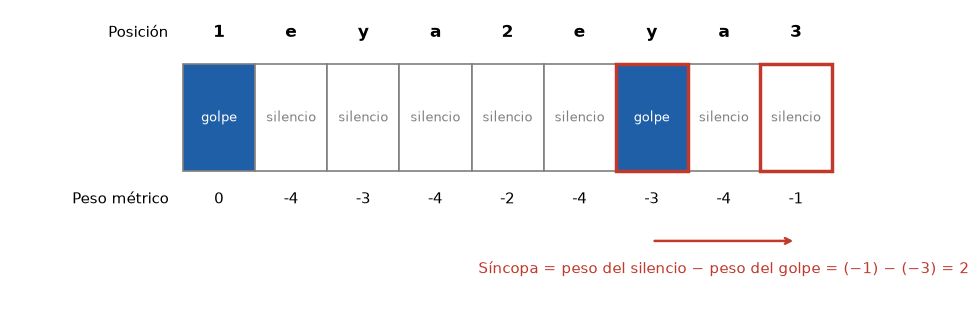

In [167]:
sounded = {0, 6}
fig, ax = plt.subplots(figsize=(10, 3.2))
for i in range(9):
    filled = i in sounded
    ax.add_patch(Rectangle((i, 0), 1, 1, facecolor="#1f5fa8" if filled else "white",
                           edgecolor="#7f7f7f", linewidth=1.2))
    ax.text(i + 0.5, 0.5, "golpe" if filled else "silencio", ha="center", va="center", fontsize=9,
            color="white" if filled else "#7f7f7f")
    ax.text(i + 0.5, 1.25, POS_LABELS[i], ha="center", fontsize=12, fontweight="bold")
    ax.text(i + 0.5, -0.3, f"{LHL_WEIGHTS[i]}", ha="center", fontsize=11)
for cell in (6, 8):
    ax.add_patch(Rectangle((cell, 0), 1, 1, facecolor="none", edgecolor="#c0392b", linewidth=2.5))
ax.annotate("", xy=(8.5, -0.65), xytext=(6.5, -0.65),
            arrowprops=dict(arrowstyle="->", color="#c0392b", lw=1.8))
ax.text(7.5, -0.95, "Síncopa = peso del silencio − peso del golpe = (−1) − (−3) = 2",
        ha="center", color="#c0392b", fontsize=11)
ax.text(-0.2, 1.25, "Posición", ha="right", fontsize=11)
ax.text(-0.2, -0.3, "Peso métrico", ha="right", fontsize=11)
ax.set_xlim(-2.4, 9.3)
ax.set_ylim(-1.2, 1.5)
ax.axis("off")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig_syncopation_example.png", dpi=300, bbox_inches="tight")
plt.show()

#### Cálculo del índice de síncopa

`syncopation_features` suma la intensidad de todas las síncopas de la interpretación y la divide entre el número de compases (`syncopation`). Se muestra cuántas interpretaciones no tienen ninguna síncopa y la mediana por grupo.

In [168]:
sync = by_perf.apply(lambda g: pd.Series(syncopation_features(g, bpm_by_id[g.name]))).reindex(final["id"])
sync.to_csv(RESULTS_DIR / "03_features_syncopation.csv")

zero = (sync["syncopation"] == 0)
print("Tamaño:", sync.shape, "| valores vacíos:", int(sync.isna().sum().sum()))
print(f"Interpretaciones sin síncopa: {int(zero.sum())} de {len(sync)} ({100 * zero.mean():.1f} %)")
print("\nMediana por tipo de fragmento y género:")
display(median_by_group(sync).round(3))

Tamaño: (687, 1) | valores vacíos: 0
Interpretaciones sin síncopa: 302 de 687 (44.0 %)

Mediana por tipo de fragmento y género:


beat_type     beat                    fill                
genre         funk   jazz  latin rock funk jazz latin rock
syncopation  0.067  0.884  0.114  0.2  0.0  0.0   0.0  0.0

### 4.2.3.6. Resumen de las características temporales

#### Tabla 12. Mediana de las características de distribución temporal en los *beats* de cada género

Se unen las 13 características temporales (Tabla 11) en una sola tabla y se calcula su mediana en los *beats*. La versión con *beats* y *fills* se guarda en `03_temporal_by_genre_type.csv`.

In [169]:
temporal = pd.concat([micro, position, ioi, sync], axis=1)
temporal.to_csv(RESULTS_DIR / "03_features_temporal.csv")
median_by_group(temporal).to_csv(RESULTS_DIR / "03_temporal_by_genre_type.csv")

print("Tamaño:", temporal.shape, "| valores vacíos:", int(temporal.isna().sum().sum()))
display(median_by_group(temporal, "beat").round(3))

Tamaño: (687, 13) | valores vacíos: 0


genre,funk,jazz,latin,rock
micro_mean,-0.055,-0.038,-0.078,-0.033
micro_abs_mean,0.144,0.232,0.181,0.171
micro_std,0.160,0.252,0.195,0.178
pos_strong,0.178,0.210,0.175,0.215
pos_backbeat,0.191,0.218,0.170,0.212
pos_8th_offbeat,0.275,0.236,0.276,0.267
pos_16th_offbeat,0.325,0.359,0.382,0.303
ioi_short,0.142,0.127,0.311,0.085
ioi_16th,0.511,0.215,0.512,0.372
ioi_triplet,0.059,0.157,0.070,0.058


## 4.2.4. Características de dinámica

### Piezas incluidas

Las características por pieza se calculan para las tres piezas con más golpes (Tabla 7).

In [170]:
top3 = piece_table.loc[DYNAMICS_PIECES, "pct_hits"]
print("Piezas incluidas:", [PIECE_NAMES[p] for p in DYNAMICS_PIECES])
print(f"Porcentaje de golpes que reúnen: {top3.sum():.1f} %")

Piezas incluidas: ['Bombo', 'Caja', 'Charles cerrado']
Porcentaje de golpes que reúnen: 74.4 %


### Cálculo de las 12 características (Tabla 13)

`dynamics_features` calcula la media, la desviación típica y el rango de la velocidad MIDI de todos los golpes (`vel_*`) y de cada una de las tres piezas (`vel_<pieza>_*`). Si una pieza no suena, sus tres valores son 0.

In [171]:
dynamics = pd.DataFrame(
    [dynamics_features(load_notes(DATA_DIR / path)) for path in final["midi_filename"]],
    index=final["id"],
)
dynamics.to_csv(RESULTS_DIR / "03_features_dynamics.csv")
print("Tamaño:", dynamics.shape, "| valores vacíos:", int(dynamics.isna().sum().sum()))

Tamaño: (687, 12) | valores vacíos: 0


### Tabla 14. Porcentaje de interpretaciones en las que no suena cada pieza

In [172]:
mean_cols = [f"vel_{p}_mean" for p in DYNAMICS_PIECES]
absence = 100 * (dynamics[mean_cols] == 0)
absence_by_group = (absence.join(labels).groupby(["beat_type", "genre"])[mean_cols].mean().T).round(1)
absence_by_group.index = [PIECE_NAMES[p] for p in DYNAMICS_PIECES]
absence_by_group.to_csv(RESULTS_DIR / "03_dynamics_absence_by_genre_type.csv")
display(absence_by_group)

beat_type       beat                    fill                  
genre           funk  jazz latin  rock  funk  jazz latin  rock
Bombo            0.0   4.2   0.0   4.9  26.2  43.1  15.2  26.9
Caja             0.0   6.2   0.0   2.0   0.0   3.9   0.0   5.4
Charles cerrado  1.9  25.0   4.2  27.5  31.8  21.6  30.4  39.2

### Tabla 15. Mediana de las características de dinámica en los *beats* de cada género

Para cada pieza, la mediana se calcula solo con las interpretaciones en las que esa pieza suena: sus ceros se sustituyen por vacíos únicamente para esta descripción. Los modelos reciben la tabla original, con ceros.

In [173]:
dyn_present = dynamics.copy()
for p in DYNAMICS_PIECES:
    piece_cols = [f"vel_{p}_mean", f"vel_{p}_std", f"vel_{p}_range"]
    dyn_present.loc[dyn_present[f"vel_{p}_mean"] == 0, piece_cols] = np.nan

median_by_group(dyn_present).round(1).to_csv(RESULTS_DIR / "03_dynamics_present_by_genre_type.csv")
display(median_by_group(dyn_present, "beat").round(1))

genre,funk,jazz,latin,rock
vel_mean,62.3,70.9,60.1,81.8
vel_std,34.2,28.6,29.8,29.5
vel_range,121.0,120.0,121.0,114.0
vel_kick_mean,57.6,63.2,33.8,65.1
vel_kick_std,14.5,12.2,13.7,14.1
vel_kick_range,85.0,59.5,55.0,65.5
vel_snare_mean,68.5,79.9,60.5,93.2
vel_snare_std,35.0,24.2,27.8,23.1
vel_snare_range,119.0,106.0,120.0,95.5
vel_hihat_closed_mean,63.5,69.4,63.1,73.2


## 4.2.5. Vector final de características

### Tabla 16. Composición del vector final

Se unen los tres grupos de características por el identificador de cada interpretación (`id`), se comprueba que no hay valores vacíos ni columnas constantes y se añaden las columnas de identificación (archivo, baterista, género, tipo de fragmento y partición). El resultado se guarda en `03_features_all.csv`.

In [174]:
groups = {"Actividad por pieza": activity, "Distribución temporal": temporal, "Dinámica": dynamics}
features = pd.concat(groups.values(), axis=1)

print("Número de características por grupo:", {name: df.shape[1] for name, df in groups.items()})
print("Total de características:", features.shape[1])
print("Valores vacíos:", int(features.isna().sum().sum()))
print("Columnas constantes:", int((features.nunique() == 1).sum()))
print("Nombres de columna repetidos:", int(features.columns.duplicated().sum()))

ID_COLS = ["midi_filename", "drummer", "genre", "beat_type", "split"]
dataset = final.set_index("id")[ID_COLS].join(features)
dataset.to_csv(RESULTS_DIR / "03_features_all.csv")
print("\nTabla guardada:", dataset.shape, "| interpretaciones por partición:",
      dataset["split"].value_counts().reindex(["train", "validation", "test"]).to_dict())

Número de características por grupo: {'Actividad por pieza': 19, 'Distribución temporal': 13, 'Dinámica': 12}
Total de características: 44
Valores vacíos: 0
Columnas constantes: 0
Nombres de columna repetidos: 0

Tabla guardada: (687, 49) | interpretaciones por partición: {'train': 539, 'validation': 79, 'test': 69}
